# PoC - model


Dane bior? z przygotowanie_danych.ipynb (osoba 1).


0 Chihuahua (n02085620-Chihuahua)
1 Japanese_spaniel (n02085782-Japanese_spaniel)
2 black-and-tan_coonhound (n02089078-black-and-tan_coonhound)
3 Scottish_deerhound (n02092002-Scottish_deerhound)
4 Weimaraner (n02092339-Weimaraner)
5 Norfolk_terrier (n02094114-Norfolk_terrier)
6 Airedale (n02096051-Airedale)
7 Australian_terrier (n02096294-Australian_terrier)
8 German_shepherd (n02106662-German_shepherd)
9 African_hunting_dog (n02116738-African_hunting_dog)
Liczba zdjęć: 1779
0 Chihuahua 152
1 Japanese_spaniel 185
2 black-and-tan_coonhound 159
3 Scottish_deerhound 232
4 Weimaraner 160
5 Norfolk_terrier 172
6 Airedale 202
7 Australian_terrier 196
8 German_shepherd 152
9 African_hunting_dog 169
[(WindowsPath('data/Images/n02085620-Chihuahua/n02085620_10074.jpg'), 0), (WindowsPath('data/Images/n02085620-Chihuahua/n02085620_10131.jpg'), 0), (WindowsPath('data/Images/n02085620-Chihuahua/n02085620_10621.jpg'), 0)]
train: 1423
val:   178
test:  178
0 Chihuahua train: 122 val: 15 test: 15
1 Ja

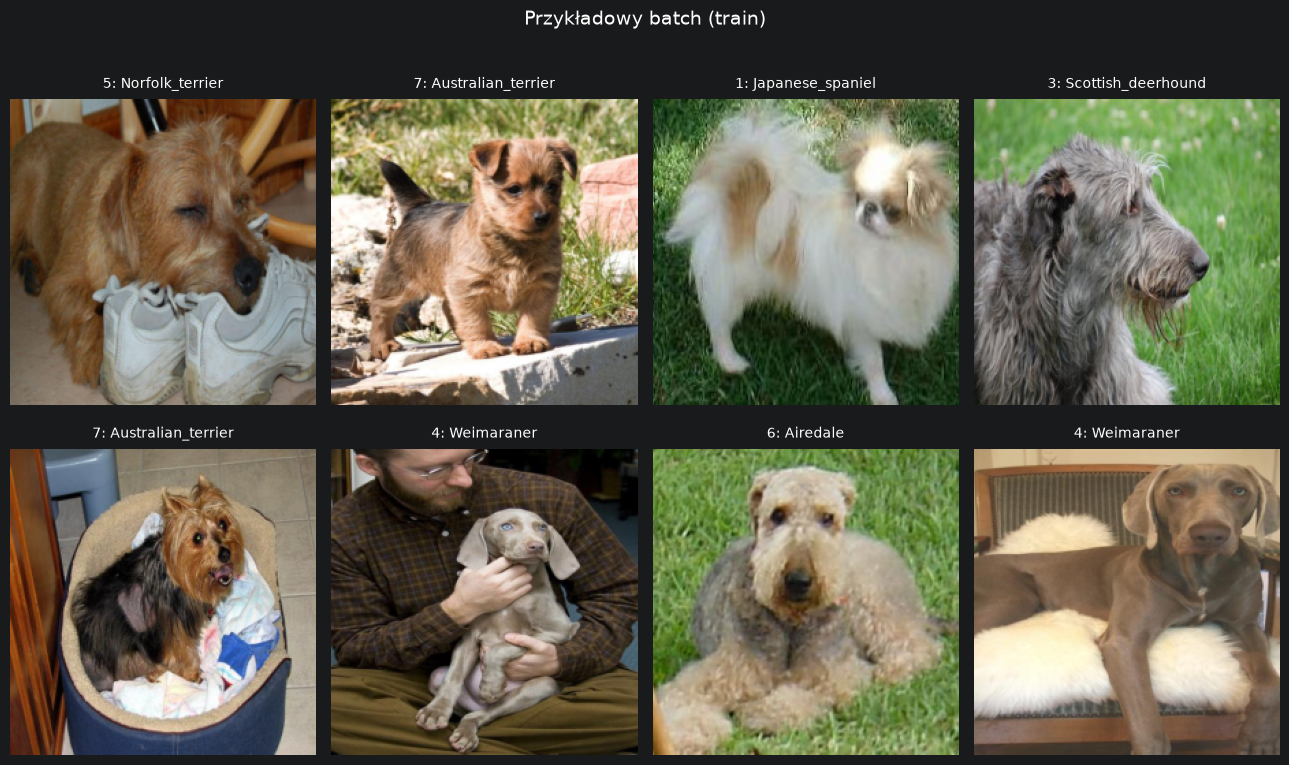

In [8]:
%run przygotowanie_danych.ipynb


Device


In [9]:
import torch
import torch.nn as nn
from torchvision import models
from PIL import Image
import matplotlib.pyplot as plt

NUM_CLASSES = 10
EPOCHS = 5
LR = 0.001

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("device:", device)


device: cpu


Model


In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=LR)

print(model.fc)


Linear(in_features=512, out_features=10, bias=True)


Trening


In [11]:
for epoch in range(EPOCHS):
    model.train()
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        opt.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        opt.step()

        preds = logits.argmax(dim=1)
        correct = correct + (preds == labels).sum().item()
        total = total + labels.size(0)

    train_acc = correct / total

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            preds = model(images).argmax(dim=1)
            correct = correct + (preds == labels).sum().item()
            total = total + labels.size(0)

    val_acc = correct / total
    print("epoch", epoch + 1, "train_acc", train_acc, "val_acc", val_acc)


epoch 1 train_acc 0.7224174279690794 val_acc 0.3202247191011236
epoch 2 train_acc 0.8812368236120871 val_acc 0.5786516853932584
epoch 3 train_acc 0.9191848208011244 val_acc 0.6235955056179775
epoch 4 train_acc 0.9255094869992972 val_acc 0.797752808988764
epoch 5 train_acc 0.9304286718200984 val_acc 0.6853932584269663


Predykcja


true: Japanese_spaniel
pred: Japanese_spaniel


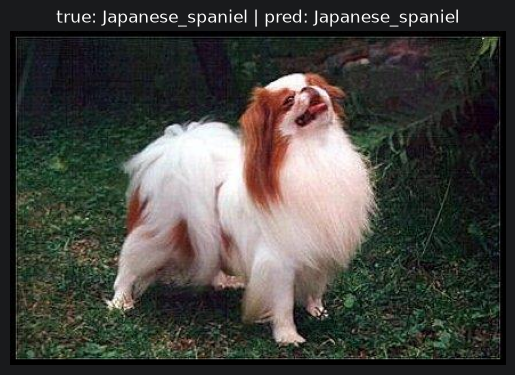

In [12]:
path, true_y = val_samples[0]
img = Image.open(path)
img = img.convert("RGB")

x = tfm(img)
x = x.unsqueeze(0)
x = x.to(device)

model.eval()
with torch.no_grad():
    pred = model(x).argmax(dim=1).item()

true_name = ladna_nazwa(id_to_class[true_y])
pred_name = ladna_nazwa(id_to_class[pred])

print("true:", true_name)
print("pred:", pred_name)

plt.imshow(img)
plt.title("true: " + true_name + " | pred: " + pred_name)
plt.axis("off")
plt.show()
